# Named Entity Recognition (NER) on CoNLL-2003
Goal: read a sentence and label every word as part of a person (PER), organization (ORG), location (LOC), miscellaneous name (MISC), or nothing (O).

> *"Barack Obama`PER` visited Microsoft`ORG` in Seattle`LOC`."*

This is sequence labeling: unlike the complaint project (one label per text), here we predict one label per word.

Plan (follows the project brief):
1. Load & explore CoNLL-2003
2. IOB tagging scheme (convert the raw IOB1 tags -> standard IOB2)
3. Vocabularies, OOV handling with character-level embeddings, pre-trained GloVe word vectors
4. Train 3 models from scratch: LSTM, BiLSTM, BiLSTM + CRF
5. Fine-tune a transformer (DistilBERT) for token classification with HuggingFace `AutoTokenizer`, `AutoModelForTokenClassification`, `Trainer`, tokens aligned with labels
6. Evaluate with seqeval: per-entity precision / recall / F1 for PER, ORG, LOC, MISC
7. Compare the 4 models + where the CRF improves boundary detection
8. Visualize predicted entities with color-coded labels
9. Deploy (Gradio app, `app.py`)

## 0. Setup, imports and settings
- Everything runs on PyTorch (GPU). The from-scratch models live in `ner_utils.py` (shared with the Gradio app, so the app processes text exactly like training).


In [1]:
# ---- Imports & Global Settings ----
import os, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from collections import Counter
from IPython.display import HTML, display
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.scheme import IOB2

import ner_utils as nu      # our own file: data reading, vocab, models, highlighting

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("torch", torch.__version__)
os.makedirs("models", exist_ok=True)

Device: cuda | NVIDIA GeForce RTX 3060 Ti
torch 2.6.0+cu124


## 1. Load & explore the dataset
CoNLL-2003 = Reuters news sentences (1996-97), hand-labeled. It comes in 3 official splits:
- `eng.train` -> train (learn), `eng.testa` -> validation (pick the best epoch), `eng.testb` -> test (final score, never used for decisions).

Each line of a file is: `word  POS-tag  chunk-tag  NER-tag`. We keep the word and the NER tag.

In [2]:
# ---- Load the three CoNLL-2003 splits ----
raw = {split: nu.read_conll(f"data/eng.{f}") for split, f in
       [("train", "train"), ("val", "testa"), ("test", "testb")]}
for split, sents in raw.items():
    print(f"{split:<5}: {len(sents):>6,} sentences | {sum(len(w) for w, _ in sents):>7,} tokens")

words, tags = raw["train"][0]
print("\nFirst training sentence:")
print(pd.DataFrame({"word": words, "raw tag": tags}).T.to_string(header=False))

train: 14,041 sentences | 203,621 tokens


val  :  3,250 sentences |  51,362 tokens
test :  3,453 sentences |  46,435 tokens

First training sentence:
word        EU  rejects  German  call  to  boycott  British  lamb  .
raw tag  I-ORG        O  I-MISC     O   O        O   I-MISC     O  O


## 2. The IOB tagging scheme
A name can be several words ("European Commission"), so each word's tag says where it is inside the entity:
- B-X = Beginning of an entity of type X
- I-X = Inside (continuation of) entity X
- O = Outside any entity

The original files use an older variant (IOB1): entities start with `I-`, and `B-` only appears when two same-type entities touch. Modern tools (seqeval, HuggingFace) expect IOB2: *every* entity starts with `B-`. So we convert.

In [3]:
# ---- Convert IOB1 -> IOB2 ----
example = ["I-ORG", "I-ORG", "O", "I-PER", "I-PER", "I-LOC", "B-LOC"]
print("IOB1:", example)
print("IOB2:", nu.iob1_to_iob2(example))

data = {split: [(w, nu.iob1_to_iob2(t)) for w, t in sents] for split, sents in raw.items()}

TAGS = ["B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC", "O"]   # 4 types x (B, I) + O
tag2id = {t: i for i, t in enumerate(TAGS)}
id2tag = {i: t for t, i in tag2id.items()}
print("\nTag set:", TAGS)

IOB1: ['I-ORG', 'I-ORG', 'O', 'I-PER', 'I-PER', 'I-LOC', 'B-LOC']
IOB2: ['B-ORG', 'I-ORG', 'O', 'B-PER', 'I-PER', 'B-LOC', 'B-LOC']

Tag set: ['B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC', 'O']


In [4]:
# ---- Entity Counts per Type (how many PER / ORG / LOC / MISC names in each split) ----
def count_entities(sents):
    return Counter(etype for _, ts in sents for etype, _, _ in nu.tags_to_spans(ts))

ent_counts = pd.DataFrame({split: count_entities(s) for split, s in data.items()}).loc[["PER", "ORG", "LOC", "MISC"]]
print(ent_counts)

tok_counts = Counter(t for _, ts in data["train"] for t in ts)
print(f"\nShare of training tokens that are 'O' (not an entity): {tok_counts['O'] / sum(tok_counts.values()):.1%}")

      train   val  test
PER    6600  1842  1617
ORG    6321  1341  1661
LOC    7140  1837  1668
MISC   3438   922   702

Share of training tokens that are 'O' (not an entity): 83.3%


Reading the numbers: ~83% of words are `O`. That's why we don't use plain accuracy, a model that predicts `O` for everything would score 83% and find zero names.
seqeval scores whole entities: an entity counts as correct only if its type and both boundaries are exactly right.

count    14041.0
mean        14.5
std         11.6
min          1.0
50%         10.0
90%         32.0
99%         46.0
max        113.0
dtype: float64


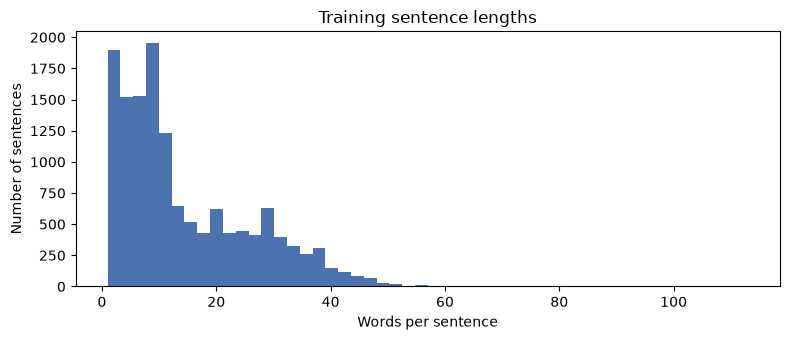

In [5]:
# ---- Sentence Length Distribution (words per sentence, train) ----
lens = pd.Series([len(w) for w, _ in data["train"]])
print(lens.describe(percentiles=[.5, .9, .99]).round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(lens, bins=50, color="#4C72B0")
ax.set_xlabel("Words per sentence"); ax.set_ylabel("Number of sentences")
ax.set_title("Training sentence lengths")
plt.tight_layout(); plt.show()

Reading the chart: x-axis = sentence length, y-axis = how many sentences have that length. Most sentences are short (median ~10 words); a few go past 100. The RNN models handle any length (we pad per batch). For the transformer we cap at 128 sub-word tokens, which covers almost every sentence.

## 3. Vocabularies, OOV handling & GloVe embeddings
Neural networks only understand numbers, so every word and every character gets an ID.

Word vectors, GloVe (pre-trained): GloVe was trained on 6 billion words of Wikipedia + news. Each word = 100 numbers, and similar words have similar vectors ("paris" ≈ "london"). Starting from these vectors means our models already "know" a lot about words before training.
- Word lookup key = lowercase, digits -> 0 (`1996` -> `0000`), because GloVe is lowercase.
- Vocabulary = all training words + any word from val/test that exists in GloVe (a standard trick: those vectors come from GloVe, not from the test labels, so nothing leaks).

OOV (out-of-vocabulary) words, character-level embeddings: a name never seen before ("Wqrzynski") still has letters. A small character CNN reads each word's letters and builds a second vector from them, it learns patterns like *starts with a capital*, *ends in -ville / -son / -berg*, *all caps* (often ORG like "NATO"). Because the char CNN sees the original casing, capital letters aren't lost when the word key is lowercased.

In [6]:
# ---- Get GloVe (re-uses the file if already downloaded) ----
WORD_DIM = 100
glove_path = nu.get_glove_file(WORD_DIM, folder="data")
print("GloVe file:", glove_path, f"({os.path.getsize(glove_path)/1e6:.0f} MB)")

GloVe file: data\glove.6B.100d.txt (347 MB)


In [7]:
# ---- Build Word + Character Vocabularies ----
all_keys = {nu.norm_word(w) for split in data.values() for ws, _ in split for w in ws}
glove = nu.load_glove(glove_path, all_keys)

train_keys = Counter(nu.norm_word(w) for ws, _ in data["train"] for w in ws)
word_vocab = nu.Vocab(sorted(train_keys))                        # every training word
for k in sorted(all_keys - set(train_keys)):                     # + val/test words that GloVe knows
    if k in glove:
        word_vocab.add(k)
char_vocab = nu.Vocab(sorted({c for ws, _ in data["train"] for w in ws for c in w}))

print(f"Word vocabulary: {len(word_vocab):,} | found in GloVe: {sum(w in glove for w in word_vocab.itos):,}")
print(f"Char vocabulary: {len(char_vocab)}")

# OOV check on the test set: words the word-embedding has never seen -> only the char CNN can help
test_words = [nu.norm_word(w) for ws, _ in data["test"] for w in ws]
print(f"Test tokens with NO word vector (handled by chars only): {np.mean([word_vocab.get(w) == 1 for w in test_words]):.1%}")

Word vocabulary: 21,215 | found in GloVe: 19,695
Char vocabulary: 86
Test tokens with NO word vector (handled by chars only): 1.1%


In [8]:
# ---- Embedding Matrix: row i = vector of word i ----
rng = np.random.default_rng(SEED)
emb_matrix = rng.normal(0, 0.1, (len(word_vocab), WORD_DIM)).astype("float32")   # random for words not in GloVe
emb_matrix[0] = 0                                                                 # <PAD> = all zeros
for w, i in word_vocab.stoi.items():
    if w in glove:
        emb_matrix[i] = glove[w]
print("Embedding matrix shape:", emb_matrix.shape)
del glove   # free memory

Embedding matrix shape: (21215, 100)


## 4. The three from-scratch models
All three share the same input layer so the comparison is fair:

`word -> [GloVe vector (100) ; char-CNN vector (50)] -> recurrent layer (200 units) -> score for each of the 9 tags`

| Model | What changes | Intuition |
|---|---|---|
| LSTM | reads the sentence left -> right only | when tagging "Bank" in "Bank of England", it hasn't seen "of England" yet |
| BiLSTM | a 2nd LSTM reads right -> left; both are combined | every word sees its full context, both sides |
| BiLSTM + CRF | adds a CRF layer on top | instead of choosing each tag on its own, it picks the best whole sequence and learns rules like *"I-PER can't follow O"* |

Training: Adam optimizer, batches of 32 sentences, dropout 0.5, gradient clipping (stops exploding gradients in RNNs). After every epoch we compute the validation entity F1 and keep the best epoch (early stopping, patience 3).

In [9]:
# ---- Training + Evaluation Helpers (from-scratch models) ----
EPOCHS = 20
PATIENCE = 3
BATCH = 32
results, test_preds, train_curves = {}, {}, {}
test_words_list = [ws for ws, _ in data["test"]]
y_test = [ts for _, ts in data["test"]]

def batches(sents, shuffle):
    idx = list(range(len(sents)))
    if shuffle:
        random.shuffle(idx)
    for i in range(0, len(idx), BATCH):
        chunk = [sents[j] for j in idx[i:i + BATCH]]
        w, c, l = nu.encode_batch([s[0] for s in chunk], word_vocab, char_vocab, DEVICE)
        t = torch.zeros_like(w)
        for r, (_, ts) in enumerate(chunk):
            t[r, :len(ts)] = torch.tensor([tag2id[x] for x in ts])
        yield w, c, l, t

def predict_tags(model, sentences):
    model.eval()
    out = []
    for i in range(0, len(sentences), 256):
        w, c, l = nu.encode_batch(sentences[i:i + 256], word_vocab, char_vocab, DEVICE)
        out += [[id2tag[x] for x in p] for p in model.predict(w, c, l)]
    return out

def evaluate(name, y_true, y_pred, train_time):
    results[name] = {"precision": precision_score(y_true, y_pred, mode="strict", scheme=IOB2),
                     "recall":    recall_score(y_true, y_pred, mode="strict", scheme=IOB2),
                     "f1":        f1_score(y_true, y_pred, mode="strict", scheme=IOB2),
                     "train_time_min": train_time / 60}
    rep = classification_report(y_true, y_pred, mode="strict", scheme=IOB2, output_dict=True)
    for e in ["PER", "ORG", "LOC", "MISC"]:
        results[name][f"f1_{e}"] = rep[e]["f1-score"] if e in rep else 0.0
    test_preds[name] = y_pred
    print(f"\n===== {name}, test set (entity level, seqeval strict IOB2) =====")
    print(classification_report(y_true, y_pred, mode="strict", scheme=IOB2, digits=3))

def train_rnn(name, bidirectional, use_crf):
    torch.manual_seed(SEED); random.seed(SEED)
    model = nu.RNNTagger(len(word_vocab), len(char_vocab), len(TAGS), emb_matrix, WORD_DIM,
                         bidirectional=bidirectional, use_crf=use_crf).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    val_words = [ws for ws, _ in data["val"]]; val_true = [ts for _, ts in data["val"]]
    best_f1, best_state, bad, curve = -1, None, 0, []
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train(); total = 0
        for w, c, l, t in batches(data["train"], shuffle=True):
            opt.zero_grad()
            loss = model.loss(w, c, l, t)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); total += loss.item()
        val_f1 = f1_score(val_true, predict_tags(model, val_words), mode="strict", scheme=IOB2)
        curve.append(val_f1)
        print(f"epoch {epoch:>2} | train loss {total:9.1f} | val F1 {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1, bad = val_f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"early stop, best val F1 {best_f1:.4f}"); break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    train_curves[name] = curve
    evaluate(name, y_test, predict_tags(model, test_words_list), train_time)
    nu.save_rnn_model(model, word_vocab, char_vocab, TAGS, f"models/{name.replace(' ', '')}")
    return model

In [10]:
# ---- Train Model 1: LSTM (left -> right only) ----
lstm_model = train_rnn("LSTM", bidirectional=False, use_crf=False)

epoch  1 | train loss     172.3 | val F1 0.8042


epoch  2 | train loss      65.7 | val F1 0.8491


epoch  3 | train loss      50.5 | val F1 0.8598


epoch  4 | train loss      42.6 | val F1 0.8721


epoch  5 | train loss      36.6 | val F1 0.8803


epoch  6 | train loss      32.6 | val F1 0.8820


... (8 outputs left out)

epoch 15 | train loss      15.7 | val F1 0.8925


epoch 16 | train loss      14.4 | val F1 0.8917


epoch 17 | train loss      13.6 | val F1 0.8916
early stop, best val F1 0.8943



===== LSTM, test set (entity level, seqeval strict IOB2) =====
              precision    recall  f1-score   support

         LOC      0.835     0.906     0.869      1668
        MISC      0.692     0.758     0.723       702
         ORG      0.825     0.734     0.777      1661
         PER      0.955     0.910     0.932      1617

   micro avg      0.846     0.839     0.842      5648
   macro avg      0.827     0.827     0.825      5648
weighted avg      0.849     0.839     0.842      5648



In [11]:
# ---- Train Model 2: BiLSTM (both directions) ----
bilstm_model = train_rnn("BiLSTM", bidirectional=True, use_crf=False)

epoch  1 | train loss     148.6 | val F1 0.8504


epoch  2 | train loss      51.2 | val F1 0.8986


epoch  3 | train loss      35.5 | val F1 0.9126


epoch  4 | train loss      28.1 | val F1 0.9221


epoch  5 | train loss      23.6 | val F1 0.9242


epoch  6 | train loss      19.9 | val F1 0.9287


... (9 outputs left out)

epoch 16 | train loss       6.3 | val F1 0.9371


epoch 17 | train loss       5.7 | val F1 0.9344


epoch 18 | train loss       5.1 | val F1 0.9334
early stop, best val F1 0.9384



===== BiLSTM, test set (entity level, seqeval strict IOB2) =====
              precision    recall  f1-score   support

         LOC      0.884     0.938     0.910      1668
        MISC      0.796     0.796     0.796       702
         ORG      0.873     0.857     0.865      1661
         PER      0.968     0.938     0.953      1617

   micro avg      0.893     0.897     0.895      5648
   macro avg      0.880     0.882     0.881      5648
weighted avg      0.894     0.897     0.895      5648



In [12]:
# ---- Train Model 3: BiLSTM + CRF ----
crf_model = train_rnn("BiLSTM+CRF", bidirectional=True, use_crf=True)

epoch  1 | train loss    1838.6 | val F1 0.8739


epoch  2 | train loss     617.7 | val F1 0.9079


epoch  3 | train loss     423.8 | val F1 0.9205


epoch  4 | train loss     322.8 | val F1 0.9267


epoch  5 | train loss     267.4 | val F1 0.9320


epoch  6 | train loss     222.1 | val F1 0.9383


... (7 outputs left out)

epoch 14 | train loss      75.2 | val F1 0.9416


epoch 15 | train loss      70.9 | val F1 0.9411


epoch 16 | train loss      61.6 | val F1 0.9392
early stop, best val F1 0.9417



===== BiLSTM+CRF, test set (entity level, seqeval strict IOB2) =====
              precision    recall  f1-score   support

         LOC      0.916     0.934     0.925      1668
        MISC      0.766     0.836     0.800       702
         ORG      0.878     0.859     0.868      1661
         PER      0.964     0.943     0.953      1617

   micro avg      0.898     0.902     0.900      5648
   macro avg      0.881     0.893     0.887      5648
weighted avg      0.900     0.902     0.901      5648



## 5. Fine-tuned Transformer (HuggingFace DistilBERT) for token classification
A transformer was pre-trained on huge amounts of English text. We add a small layer that outputs one of our 9 tags per token, then fine-tune.

Note: `distilbert-base-uncased` is *uncased* (sees "apple" and "Apple" the same), and capital letters are a strong NER clue, so a *cased* model would likely score a bit higher. Keep this in mind when comparing.

Token <-> label alignment (the key step): the transformer splits words into sub-words: `"Wqrzynski" -> ["w", "##q", "##rz", "##yn", "##ski"]`. We only have one label per *word*, so:
- the first sub-word of each word gets the word's label,
- the other sub-words and the special tokens `[CLS]`, `[SEP]` get -100 = "ignore this position in the loss".

At prediction time we read the tag of each word's first sub-word, so the scores are per word, the same thing the other three models are scored on.

In [13]:
# ---- Transformer Settings, Tokenizer & Label Alignment ----
from transformers import (AutoTokenizer, AutoModelForTokenClassification, TrainingArguments,
                          Trainer, DataCollatorForTokenClassification)

MODEL_NAME = os.environ.get("NER_HF_MODEL", "distilbert-base-uncased")
TF_MAX_LEN = 128
TF_EPOCHS = 3
hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def align(words, tags=None):
    enc = hf_tokenizer(words, is_split_into_words=True, truncation=True, max_length=TF_MAX_LEN)
    if tags is not None:
        labels, prev = [], None
        for wid in enc.word_ids():
            labels.append(-100 if wid is None or wid == prev else tag2id[tags[wid]])
            prev = wid
        enc["labels"] = labels
    return enc

ex_words, ex_tags = data["train"][0]
ex = align(ex_words, ex_tags)
print(pd.DataFrame({"sub-word": hf_tokenizer.convert_ids_to_tokens(ex["input_ids"]),
                    "word #": ex.word_ids(),
                    "label": [id2tag.get(x, "-100 (ignored)") for x in ex["labels"]]}).T.to_string(header=False))

sub-word           [CLS]     eu  rejects  german  call   to  boycott  british  lamb    .           [SEP]
word #               NaN    0.0      1.0     2.0   3.0  4.0      5.0      6.0   7.0  8.0             NaN
label     -100 (ignored)  B-ORG        O  B-MISC     O    O        O   B-MISC     O    O  -100 (ignored)


In [14]:
# ---- Wrap data for the Trainer ----
class NERDataset(torch.utils.data.Dataset):
    def __init__(self, sents):
        self.items = [align(ws, ts) for ws, ts in sents]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return dict(self.items[i])

train_ds, val_ds = NERDataset(data["train"]), NERDataset(data["val"])
print("Transformer train sentences:", len(train_ds), "| val:", len(val_ds))

Transformer train sentences: 14041 | val: 3250


In [15]:
# ---- Trainer setup ----
def hf_predict_words(model, sentences):
    # per-word tags = tag of each word's FIRST sub-word (words cut off by truncation -> 'O')
    model.eval(); out = []
    for i in range(0, len(sentences), 64):
        chunk = sentences[i:i + 64]
        enc = hf_tokenizer(chunk, is_split_into_words=True, truncation=True, max_length=TF_MAX_LEN,
                           padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad():
            pred = model(**enc).logits.argmax(-1).cpu().numpy()
        for b, ws in enumerate(chunk):
            tags, seen = ["O"] * len(ws), set()
            for pos, wid in enumerate(enc.word_ids(b)):
                if wid is not None and wid not in seen:
                    seen.add(wid); tags[wid] = id2tag[int(pred[b, pos])]
            out.append(tags)
    return out

def hf_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    y_t = [[id2tag[l] for l in lab if l != -100] for lab in labels]
    y_p = [[id2tag[p] for p, l in zip(pr, lab) if l != -100] for pr, lab in zip(preds, labels)]
    return {"f1": f1_score(y_t, y_p, mode="strict", scheme=IOB2)}

tf_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=len(TAGS), id2label=id2tag, label2id=tag2id)

BATCH_TF = 16
total_steps = int(np.ceil(len(train_ds) / BATCH_TF)) * TF_EPOCHS
args = TrainingArguments(
    output_dir="models/hf_checkpoints",
    num_train_epochs=TF_EPOCHS,
    per_device_train_batch_size=BATCH_TF,
    per_device_eval_batch_size=64,
    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_steps=int(0.1 * total_steps),     # first 10% of steps: learning rate ramps up slowly
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=200,
    fp16=(DEVICE == "cuda"),
    report_to="none",
    dataloader_num_workers=0,
    seed=SEED,
)
trainer = Trainer(model=tf_model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  data_collator=DataCollatorForTokenClassification(hf_tokenizer),
                  compute_metrics=hf_metrics)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [16]:
# ---- Train Model 4: Fine-tune DistilBERT ----
t0 = time.time()
trainer.train()
tf_train_time = time.time() - t0
print(f"Training time: {tf_train_time/60:.1f} min")

Epoch,Training Loss,Validation Loss,F1
1,0.062198,0.049635,0.927201
2,0.026533,0.046624,0.941404
3,0.012915,0.046670,0.946313


Training time: 1.7 min


In [17]:
# ---- Evaluate the Transformer on the test set + save it ----
evaluate("DistilBERT", y_test, hf_predict_words(trainer.model, test_words_list), tf_train_time)
trainer.save_model("models/DistilBERT")
hf_tokenizer.save_pretrained("models/DistilBERT")


===== DistilBERT, test set (entity level, seqeval strict IOB2) =====
              precision    recall  f1-score   support

         LOC      0.919     0.924     0.922      1668
        MISC      0.790     0.809     0.799       702
         ORG      0.875     0.871     0.873      1661
         PER      0.971     0.960     0.966      1617

   micro avg      0.905     0.905     0.905      5648
   macro avg      0.889     0.891     0.890      5648
weighted avg      0.905     0.905     0.905      5648



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('models/DistilBERT\\tokenizer_config.json',
 'models/DistilBERT\\tokenizer.json')

## 6. Compare the four models
Ranked by entity-level F1 on the test set (micro average over all entities). Columns `f1_PER` ... `f1_MISC` = F1 for each entity type.

In [18]:
# ---- Model Comparison Table ----
comparison = pd.DataFrame(results).T.sort_values("f1", ascending=False).round(4)
print(comparison.to_string())
BEST = comparison.index[0]
print(f"\nBest model: {BEST}")

            precision  recall      f1  train_time_min  f1_PER  f1_ORG  f1_LOC  f1_MISC
DistilBERT     0.9047  0.9046  0.9046          1.6786  0.9658  0.8729  0.9220   0.7994
BiLSTM+CRF     0.8981  0.9024  0.9003          6.5442  0.9534  0.8683  0.9249   0.7997
BiLSTM         0.8931  0.8966  0.8949          3.9396  0.9529  0.8649  0.9101   0.7963
LSTM           0.8457  0.8385  0.8421          3.7901  0.9319  0.7771  0.8695   0.7233

Best model: DistilBERT


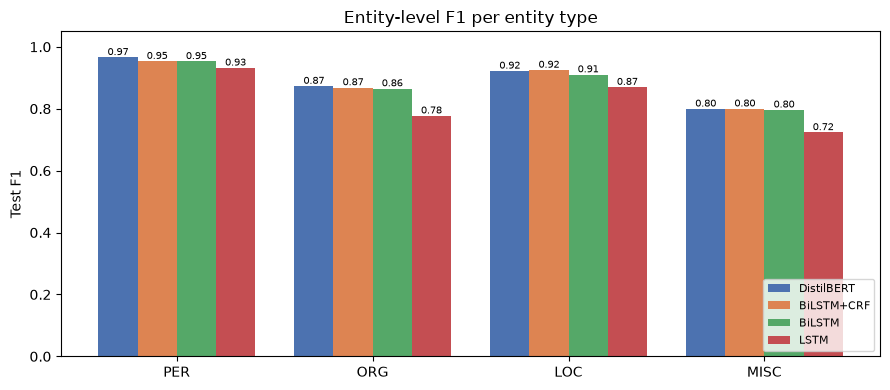

In [19]:
# ---- Per-Entity F1 by Model (grouped bar chart) ----
ents = ["PER", "ORG", "LOC", "MISC"]
order = list(comparison.index)
x = np.arange(len(ents)); width = 0.8 / len(order)
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(9, 4))
for k, name in enumerate(order):
    vals = [comparison.loc[name, f"f1_{e}"] for e in ents]
    bars = ax.bar(x + k * width - 0.4 + width / 2, vals, width, label=name, color=colors[k])
    ax.bar_label(bars, fmt="%.2f", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(ents)
ax.set_ylabel("Test F1"); ax.set_ylim(0, 1.05)
ax.set_title("Entity-level F1 per entity type")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

Reading the chart: each group of bars = one entity type; each color = one model; the number on top = its F1 (1.0 = perfect).
Typical pattern on CoNLL: PER is easiest (names look like names), MISC is hardest (a mixed bag: nationalities, events, product names), and ORG vs LOC get confused because the same word can be both ("Japan" the country = LOC, "Japan" the football team = ORG).

## 7. Where does the CRF improve boundary detection?
Without a CRF, the BiLSTM picks every word's tag on its own. That can produce sequences that are impossible in IOB2, e.g.:
- `O -> I-PER` (an entity "continues" without ever starting)
- `B-ORG -> I-LOC` (an entity changes type in the middle)

Each such slip breaks an entity's boundary, and seqeval counts the whole entity as wrong. The CRF learns a transition score for every pair of tags and uses the Viterbi algorithm to pick the best *whole* sequence, so these jumps are pushed out.

We measure it three ways:
1. Invalid transitions in each model's test predictions
2. Boundary errors: entities whose type matches a real one that overlaps it, but whose start/end are wrong
3. The learned transition matrix of the CRF

In [20]:
# ---- CRF Boundary Analysis ----
def invalid_transitions(seqs):
    bad = 0
    for tags in seqs:
        prev = "O"
        for t in tags:
            if t.startswith("I-") and (prev == "O" or prev[2:] != t[2:]):
                bad += 1
            prev = t
    return bad

def boundary_errors(true_seqs, pred_seqs):
    # predicted entities that overlap a TRUE entity of the SAME type but have different start/end
    n = 0
    for t, p in zip(true_seqs, pred_seqs):
        gold = set(nu.tags_to_spans(t))
        for etype, s, e in nu.tags_to_spans(p):
            if (etype, s, e) not in gold and any(g[0] == etype and g[1] < e and s < g[2] for g in gold):
                n += 1
    return n

boundary = pd.DataFrame({name: {"invalid transitions": invalid_transitions(test_preds[name]),
                                "boundary errors": boundary_errors(y_test, test_preds[name]),
                                "entity F1": results[name]["f1"]}
                         for name in ["LSTM", "BiLSTM", "BiLSTM+CRF", "DistilBERT"]}).T
print(boundary.to_string())

            invalid transitions  boundary errors  entity F1
LSTM                      326.0            332.0   0.842105
BiLSTM                    104.0            142.0   0.894858
BiLSTM+CRF                  3.0             90.0   0.900291
DistilBERT                 80.0            139.0   0.904648


In [21]:
# ---- Example where the CRF fixes a boundary the BiLSTM breaks ----
shown = 0
for i, (ws, gold) in enumerate(zip(test_words_list, y_test)):
    a, b = test_preds["BiLSTM"][i], test_preds["BiLSTM+CRF"][i]
    if a != gold and b == gold and invalid_transitions([a]) > 0:
        print("Sentence  :", " ".join(ws))
        diff = [j for j in range(len(ws)) if a[j] != gold[j]]
        lo, hi = max(0, diff[0] - 2), min(len(ws), diff[-1] + 3)
        print(pd.DataFrame({"word": ws[lo:hi], "true": gold[lo:hi], "BiLSTM": a[lo:hi],
                            "BiLSTM+CRF": b[lo:hi]}).T.to_string(header=False), "\n")
        shown += 1
        if shown == 3:
            break
if shown == 0:
    print("No example found in this run.")

Sentence  : FREESTYLE SKIING-WORLD CUP MOGUL RESULTS .
word        FREESTYLE  SKIING-WORLD     CUP  MOGUL
true                O        B-MISC  I-MISC      O
BiLSTM         B-MISC             O  I-MISC      O
BiLSTM+CRF          O        B-MISC  I-MISC      O 

Sentence  : Australia beat West Indies by five wickets in a World Series limited overs match at the Melbourne Cricket Ground on Friday .
word        the  Melbourne  Cricket  Ground  on
true          O      B-LOC    I-LOC   I-LOC   O
BiLSTM        O      B-LOC    I-ORG   I-LOC   O
BiLSTM+CRF    O      B-LOC    I-LOC   I-LOC   O 

Sentence  : Australia went on to win the match at the Sydney Cricket Ground by 124 runs to take a two-nil lead in the five-test series after Lara failed in both innings .
word        the  Sydney  Cricket  Ground  by  124
true          O   B-LOC    I-LOC   I-LOC   O    O
BiLSTM        O   B-LOC    I-ORG   I-ORG   O    O
BiLSTM+CRF    O   B-LOC    I-LOC   I-LOC   O    O 



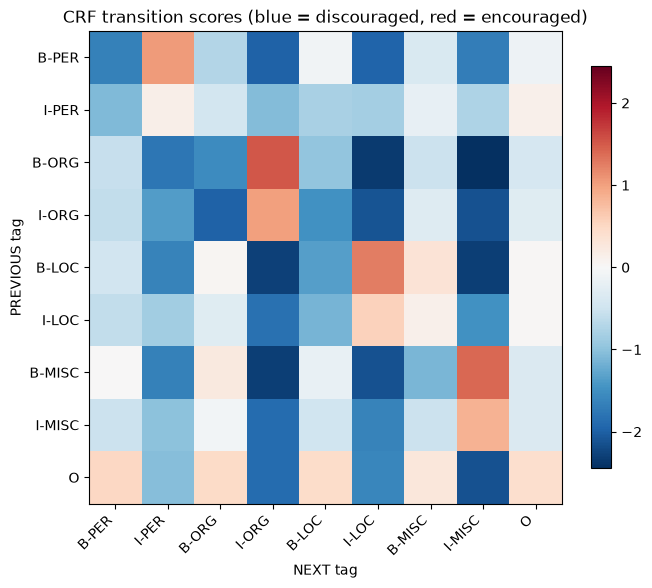

In [22]:
# ---- Learned CRF Transition Scores (heatmap) ----
trans = crf_model.crf.transitions.detach().cpu().numpy()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(trans, cmap="RdBu_r", vmin=-np.abs(trans).max(), vmax=np.abs(trans).max())
ax.set_xticks(range(len(TAGS))); ax.set_xticklabels(TAGS, rotation=45, ha="right")
ax.set_yticks(range(len(TAGS))); ax.set_yticklabels(TAGS)
ax.set_xlabel("NEXT tag"); ax.set_ylabel("PREVIOUS tag")
ax.set_title("CRF transition scores (blue = discouraged, red = encouraged)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

Reading the heatmap: row = the previous word's tag, column = the next word's tag. Blue = the CRF learned this move is unlikely, red = likely.
Look at the `I-` columns: e.g. row `O` -> column `I-PER` should be blue ("a person can't continue if it never started"), while `B-PER` -> `I-PER` should be red. The model learned the IOB grammar from data, nobody wrote these rules.

## 8. Visualize predicted entities (color-coded)
Colors: <span style="background:#ff9f9f;padding:2px 4px">PER</span> <span style="background:#9fc5ff;padding:2px 4px">ORG</span> <span style="background:#9fe0a8;padding:2px 4px">LOC</span> <span style="background:#ffd27f;padding:2px 4px">MISC</span>

In [23]:
# ---- Color-Coded Predictions of the Best Model ----
def predict_any(name, sentences):
    if name == "DistilBERT":
        return hf_predict_words(trainer.model, sentences)
    m = {"LSTM": lstm_model, "BiLSTM": bilstm_model, "BiLSTM+CRF": crf_model}[name]
    return predict_tags(m, sentences)

demo_texts = [
    "Lionel Messi signed a new contract with Inter Miami in Florida on Tuesday.",
    "The European Union and Germany criticised Microsoft over its Windows licensing in Brussels.",
    "Egyptian striker Mohamed Salah scored twice as Liverpool beat Arsenal at Anfield.",
]
sents = [[tok for tok, _, _ in nu.tokenize_with_offsets(t)] for t in demo_texts]
print(f"Model: {BEST}")
for ws, tags in zip(sents, predict_any(BEST, sents)):
    display(HTML(nu.spans_to_html(ws, tags)))

print("Test-set examples (prediction vs truth):")
for i in [0, 5, 12]:
    i = min(i, len(test_words_list) - 1)
    display(HTML("<b>pred</b> " + nu.spans_to_html(test_words_list[i], test_preds[BEST][i])))
    display(HTML("<b>true</b> " + nu.spans_to_html(test_words_list[i], y_test[i])))

Model: DistilBERT


Test-set examples (prediction vs truth):


In [24]:
# ---- Save results for the app + README ----
with open("models/results.json", "w") as f:
    json.dump({"best_model": BEST, "tags": TAGS, "results": comparison.to_dict(orient="index"),
               "crf_analysis": boundary.to_dict(orient="index"),
               "entity_counts": ent_counts.to_dict()}, f, indent=2)
print("Saved models/results.json")

Saved models/results.json


## 9. Deployment (Gradio)
The app is in `app.py` (double-click `run_app.bat`). It loads the best model from `models/`, takes free text and highlights the detected entities in real time with color-coded labels (PER, ORG, LOC, MISC).